Valeurs manquantes restantes : 0
Taille de X_train : (26048, 14)
Taille de X_test  : (6513, 14)
--- 1. Arbre de base ---
Précision : 80.81 %

--- 2. Test de max_depth (profondeur) ---
Profondeur = 3 -> Précision : 83.94 %


C:\Users\ikram\AppData\Local\Temp\ipykernel_7616\395367830.py:28: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for col in df.select_dtypes(include=['object']).columns:


Profondeur = 5 -> Précision : 85.48 %
Profondeur = 10 -> Précision : 85.89 %
Profondeur = 15 -> Précision : 84.08 %
Profondeur = 20 -> Précision : 82.77 %
Profondeur = None -> Précision : 80.81 %

--- 3. Test de min_samples_leaf ---
min_samples_leaf = 1 -> Précision : 80.81 %
min_samples_leaf = 5 -> Précision : 83.34 %
min_samples_leaf = 10 -> Précision : 84.09 %
min_samples_leaf = 20 -> Précision : 85.21 %
min_samples_leaf = 50 -> Précision : 85.55 %


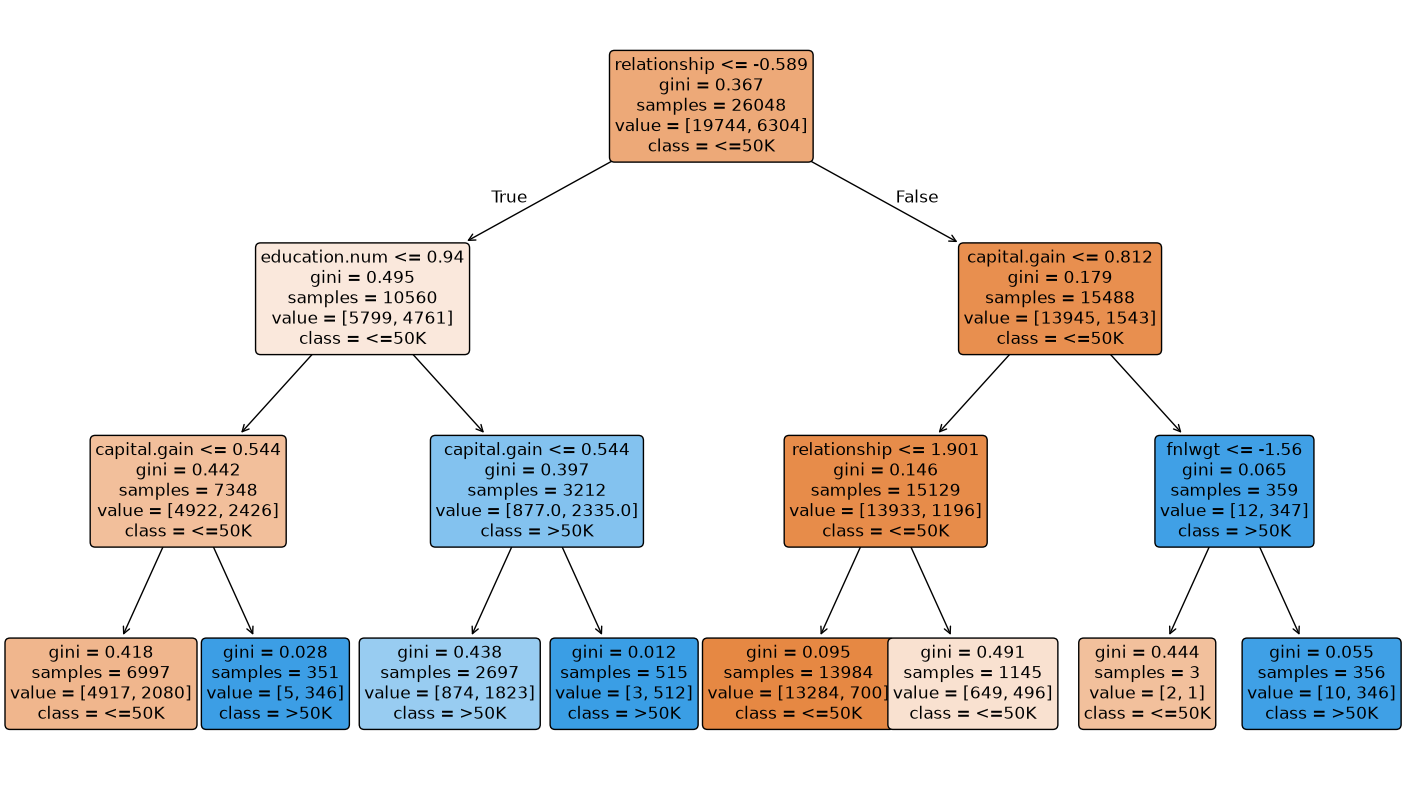

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Charger le dataset
df = pd.read_csv(r"C:\Users\ikram\data-mining-adult-income\data\adult.csv")

# Afficher les 5 premières lignes
df.head()

# Remplacer les "?" par des vraies valeurs manquantes (NaN)
# Attention : pas d'espace avant le ?, on cherche exactement ce qu'il y a dans le fichier
df = df.replace('?', np.nan)
# Remplacer par la valeur la plus fréquente (le mode) pour chaque colonne
for col in df.columns:
    if df[col].isnull().sum() > 0:
        df[col] = df[col].fillna(df[col].mode()[0])

# Vérifier s'il reste des valeurs manquantes
print("Valeurs manquantes restantes :", df.isnull().sum().sum())



from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()
for col in df.select_dtypes(include=['object']).columns:
    df[col] = le.fit_transform(df[col])

df.head() # Tout doit être en chiffres maintenant
from sklearn.preprocessing import StandardScaler

X = df.drop('income', axis=1)
y = df['income']

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
X = pd.DataFrame(X_scaled, columns=X.columns)

X.head()
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print("Taille de X_train :", X_train.shape)
print("Taille de X_test  :", X_test.shape)
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

print("--- 1. Arbre de base ---")
clf = DecisionTreeClassifier(random_state=42)
clf.fit(X_train, y_train)
print(f"Précision : {accuracy_score(y_test, clf.predict(X_test)) * 100:.2f} %\n")

print("--- 2. Test de max_depth (profondeur) ---")
for depth in [3, 5, 10, 15, 20, None]:
    clf_test = DecisionTreeClassifier(max_depth=depth, random_state=42)
    clf_test.fit(X_train, y_train)
    acc = accuracy_score(y_test, clf_test.predict(X_test))
    print(f"Profondeur = {depth} -> Précision : {acc * 100:.2f} %")

print("\n--- 3. Test de min_samples_leaf ---")
for leaf in [1, 5, 10, 20, 50]:
    clf_test = DecisionTreeClassifier(min_samples_leaf=leaf, random_state=42)
    clf_test.fit(X_train, y_train)
    acc = accuracy_score(y_test, clf_test.predict(X_test))
    print(f"min_samples_leaf = {leaf} -> Précision : {acc * 100:.2f} %")
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree

# On recrée un petit arbre lisible (profondeur 3)
meilleur_arbre = DecisionTreeClassifier(max_depth=3, random_state=42)
meilleur_arbre.fit(X_train, y_train)

# Préparation du graphique
plt.figure(figsize=(18, 10))
plot_tree(meilleur_arbre, 
          feature_names=X.columns, 
          class_names=['<=50K', '>50K'], 
          filled=True, 
          rounded=True, 
          fontsize=12)

# Sauvegarder l'image dans ton dossier results/figures
plt.savefig("../results/figures/arbre_decision.png", bbox_inches='tight')
plt.show()